# Lab 4 of 8 — Unsupervised Learning I: Clustering and PCA
**TEB3123 Machine Learning** · Muhammad Aqil Bazli Bin Jafni

*Find structure without an answer key.* Coverage: Chapters 15–17.

**Goal.** Choose K from evidence, compare DBSCAN, and evaluate PCA through reconstruction and downstream accuracy.

## Setup

In [1]:
import zipfile
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, silhouette_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

PROJECT_ROOT = Path.cwd().parent
DATA = PROJECT_ROOT / "all_datasets"
MODELS = PROJECT_ROOT / "models"
MODELS.mkdir(exist_ok=True)

## Part A — How many clusters? Elbow and silhouette
Standardize age, income, and spending score for 200 mall customers, then look for useful segments without labels.
Standardizing matters because K-means uses Euclidean distance: unscaled, the feature with the largest numeric range would dominate every distance.

In [2]:
customers = pd.read_csv(DATA / "mall_customers_dataset.csv")
print(customers.head())
print("rows:", len(customers))

features = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
X = StandardScaler().fit_transform(customers[features])

   CustomerID   Genre  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40
rows: 200


Try K = 2–8. **Inertia** (within-cluster squared distance) always falls as K grows; **silhouette** compares cohesion with separation, so it can peak.

k=2  inertia=389.4  silhouette=0.335
k=3  inertia=295.2  silhouette=0.358
k=4  inertia=205.2  silhouette=0.404


k=5  inertia=168.2  silhouette=0.417
k=6  inertia=133.9  silhouette=0.427


k=7  inertia=117.0  silhouette=0.417
k=8  inertia=103.8  silhouette=0.409


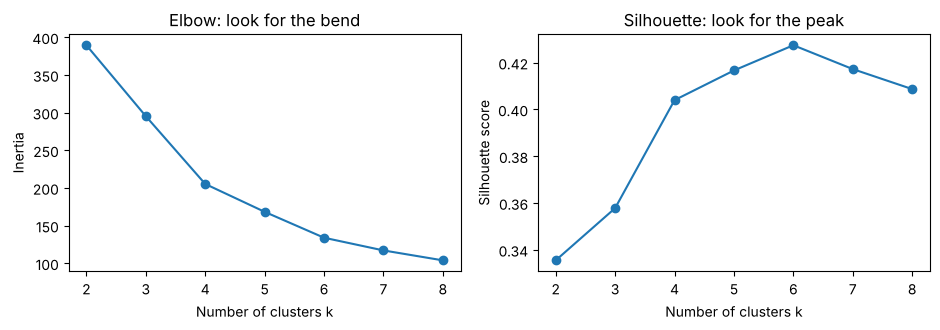

In [3]:
ks, inertias, silhouettes = [], [], []
for k in range(2, 9):
    kmeans = KMeans(n_clusters=k, n_init=20, random_state=42)
    labels = kmeans.fit_predict(X)
    ks.append(k)
    inertias.append(kmeans.inertia_)
    silhouettes.append(silhouette_score(X, labels))
    print(f"k={k}  inertia={kmeans.inertia_:.1f}  silhouette={silhouettes[-1]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.4))
axes[0].plot(ks, inertias, marker="o")
axes[0].set_xlabel("Number of clusters k")
axes[0].set_ylabel("Inertia")
axes[0].set_title("Elbow: look for the bend")
axes[1].plot(ks, silhouettes, marker="o")
axes[1].set_xlabel("Number of clusters k")
axes[1].set_ylabel("Silhouette score")
axes[1].set_title("Silhouette: look for the peak")
plt.tight_layout()
plt.show()

### Inspect — choosing K
- **Elbow:** inertia drops steeply up to k = 4–5 (389 → 205 → 168), then the gains shrink (134, 117, 104). The bend is around **k = 5**.
- **Silhouette:** rises to 0.417 at k = 5 and peaks at **0.427 at k = 6**, then falls. The difference between 5 and 6 is only 0.01 — essentially a tie.

Neither score settles it on its own, so the choice comes down to **domain usefulness**. I choose **k = 5** (profiled in Part B):
- Each of the five groups maps to a distinct, nameable marketing segment, and every group is a workable size (20–54 customers).
- Going to k = 6 mainly splits the young/moderate group into "low-income high spenders" and "mid-income average spenders". That is a real distinction, but it adds a campaign for a small group (24 customers) for a 0.01 silhouette gain.
- Five segments is a number a marketing team can realistically run separate campaigns for.

## Part B — K-means versus DBSCAN
K-means assigns **every** customer to a cluster. DBSCAN grows clusters from dense regions using a radius (`eps`) and a neighbour count (`min_samples`), and labels sparse points as noise (−1).

In [4]:
kmeans = KMeans(n_clusters=5, n_init=30, random_state=42)
k_labels = kmeans.fit_predict(X)
print("K-means silhouette:", round(silhouette_score(X, k_labels), 3))

dbscan = DBSCAN(eps=0.75, min_samples=6)
d_labels = dbscan.fit_predict(X)
is_clustered = d_labels != -1
n_clusters = len(set(d_labels[is_clustered]))
print("DBSCAN clusters:", n_clusters, "  noise points:", int((~is_clustered).sum()))
if n_clusters >= 2:
    print("DBSCAN silhouette (clustered points only):",
          round(silhouette_score(X[is_clustered], d_labels[is_clustered]), 3))

K-means silhouette: 0.417
DBSCAN clusters: 1   noise points: 14


Describe the clusters using means of the **original** (unscaled) features, so the profiles are readable.

                 Age  Annual Income (k$)  Spending Score (1-100)  customers
kmeans_cluster                                                             
0               46.2                26.8                    18.4         20
1               25.2                41.1                    62.2         54
2               32.9                86.1                    81.5         40
3               39.9                86.1                    19.4         39
4               55.6                54.4                    48.9         47


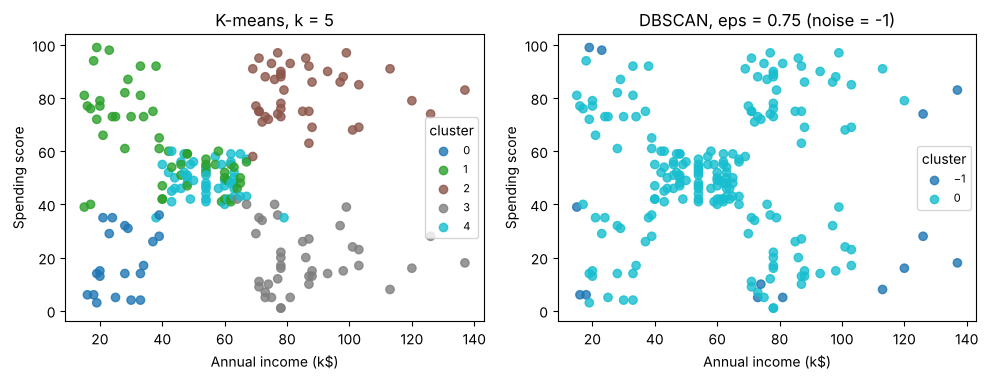

In [5]:
segments = customers.copy()
segments["kmeans_cluster"] = k_labels
segments["dbscan_cluster"] = d_labels

profile = segments.groupby("kmeans_cluster")[features].mean().round(1)
profile["customers"] = segments["kmeans_cluster"].value_counts().sort_index()
print(profile)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.9))
panels = [(axes[0], k_labels, "K-means, k = 5"),
          (axes[1], d_labels, "DBSCAN, eps = 0.75 (noise = -1)")]
for ax, labels, title in panels:
    scatter = ax.scatter(customers["Annual Income (k$)"], customers["Spending Score (1-100)"],
                         c=labels, cmap="tab10", alpha=0.8)
    ax.set_xlabel("Annual income (k$)")
    ax.set_ylabel("Spending score")
    ax.set_title(title)
    ax.legend(*scatter.legend_elements(), title="cluster", fontsize=8, loc="center right")
plt.tight_layout()
plt.show()

### Inspect — K-means segments (k = 5)
| Segment | Profile (mean age · income · spending) | Size | Marketing reading |
|---|---|---|---|
| Young spenders | ~25 yrs · 41k · 62 | 54 | Trend-driven, responsive to promotions and social media |
| Affluent high spenders | ~33 yrs · 86k · 82 | 40 | Most valuable group — loyalty / premium programmes |
| Affluent careful spenders | ~40 yrs · 86k · 19 | 39 | Can spend but don't — biggest upsell opportunity |
| Older middle-income | ~56 yrs · 54k · 49 | 47 | Steady, average customers — value and convenience messaging |
| Low-income low spenders | ~46 yrs · 27k · 18 | 20 | Price-sensitive — discounts, low priority for spend |

(Cluster numbers can be relabelled between runs; the profiles are what matter.)

### Inspect — K-means vs DBSCAN (eps = 0.75, min_samples = 6)
DBSCAN at **eps = 0.75** finds **1 cluster of 186 customers plus 14 noise points**. In standardized space this radius is wide enough that neighbouring segments link into one connected cloud, so DBSCAN has no gap to split on. The 14 noise points are mostly high-income customers at the sparse edges of the data.

The contrast comes from different assumptions: K-means assumes *K* roughly spherical groups and must partition everyone, so it always produces K segments; DBSCAN only separates regions divided by low density, and the mall data has no strong density gaps at this scale.

## Try it yourself — DBSCAN with eps = 0.5
Set `eps = 0.5`, count clusters and noise, and decide which result better serves marketing.

DBSCAN eps=0.5 clusters: 5   noise points: 66
cluster sizes: {-1: 66, 0: 16, 1: 50, 2: 29, 3: 32, 4: 7}
DBSCAN silhouette (clustered points only): 0.528
               Age  Annual Income (k$)  Spending Score (1-100)
dbscan_eps05                                                  
-1            39.7                65.5                    32.3
 0            23.4                25.3                    78.5
 1            54.2                53.3                    48.4
 2            24.4                54.5                    50.2
 3            32.8                80.9                    83.6
 4            43.9                78.7                    14.6


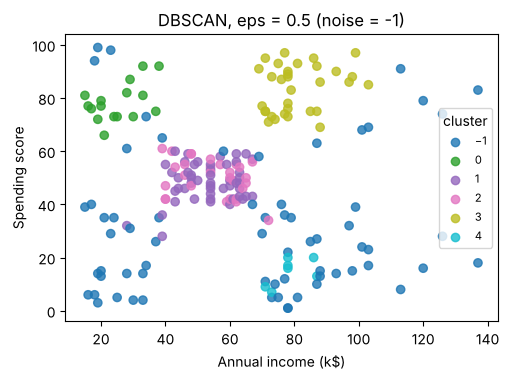

In [6]:
dbscan_small = DBSCAN(eps=0.5, min_samples=6)
d_small = dbscan_small.fit_predict(X)
clustered_small = d_small != -1
n_small = len(set(d_small[clustered_small]))
print("DBSCAN eps=0.5 clusters:", n_small, "  noise points:", int((~clustered_small).sum()))
print("cluster sizes:", pd.Series(d_small).value_counts().sort_index().to_dict())
if n_small >= 2:
    print("DBSCAN silhouette (clustered points only):",
          round(silhouette_score(X[clustered_small], d_small[clustered_small]), 3))

segments["dbscan_eps05"] = d_small
print(segments.groupby("dbscan_eps05")[features].mean().round(1))

fig, ax = plt.subplots(figsize=(5.2, 3.9))
scatter = ax.scatter(customers["Annual Income (k$)"], customers["Spending Score (1-100)"],
                     c=d_small, cmap="tab10", alpha=0.8)
ax.set_xlabel("Annual income (k$)")
ax.set_ylabel("Spending score")
ax.set_title("DBSCAN, eps = 0.5 (noise = -1)")
ax.legend(*scatter.legend_elements(), title="cluster", fontsize=8, loc="center right")
plt.tight_layout()
plt.show()

### Which result better serves marketing?
With **eps = 0.5**, DBSCAN finds **5 clusters but labels 66 customers (33%) as noise**. The clusters it does find resemble the K-means segments (young high spenders, affluent high spenders, affluent careful spenders, an older middle-income group, a young mid-income group), and its silhouette on the clustered points is higher (≈0.53 vs 0.42). That number is flattering, though: it is computed **only on the points DBSCAN kept**, after it discarded the hardest third of the data.

**K-means (k = 5) serves marketing better here.**
- Marketing needs every customer in a segment to target them; leaving a third of customers unassigned means a third of the customer base gets no campaign.
- The "noise" points are not outliers in a business sense — they are ordinary customers sitting between dense regions (mean income ≈ 66k, spending ≈ 32).
- DBSCAN is very sensitive to `eps`: 0.75 gives one useless cluster, 0.5 gives five clusters with heavy noise. K-means gives stable, interpretable segments.

DBSCAN would be the better tool if the goal were **anomaly detection** (e.g. flagging unusual customers for review) rather than full segmentation.

## Part C — PCA as compression, judged by a downstream model
Each digit is 8 × 8 = 64 pixels. Use the official training split for all choices; the official test file is used **once**, at the final comparison.

training digits: 3823   test digits: 1797


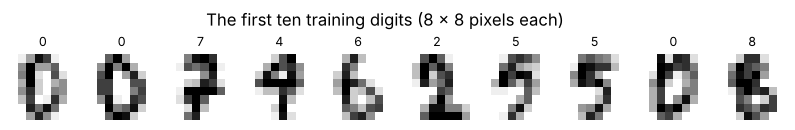

In [7]:
archive_path = DATA / "optical_recognition_handwritten_digits.zip"
columns = [f"pixel_{i}" for i in range(64)] + ["label"]

with zipfile.ZipFile(archive_path) as archive:
    members = {Path(name).name: name for name in archive.namelist()}
    train = pd.read_csv(archive.open(members["optdigits.tra"]), header=None, names=columns)
    test = pd.read_csv(archive.open(members["optdigits.tes"]), header=None, names=columns)

X_dev = train.drop(columns="label") / 16.0   # pixel values 0-16 -> 0-1
y_dev = train["label"]
X_test = test.drop(columns="label") / 16.0
y_test = test["label"]
print("training digits:", len(X_dev), "  test digits:", len(X_test))

fig, axes = plt.subplots(1, 10, figsize=(10, 1.4))
for ax, (_, row), label in zip(axes, X_dev.head(10).iterrows(), y_dev.head(10)):
    ax.imshow(row.to_numpy().reshape(8, 8), cmap="gray_r")
    ax.set_title(str(label), fontsize=9)
    ax.axis("off")
plt.suptitle("The first ten training digits (8 x 8 pixels each)", y=1.05)
plt.show()

Validate PCA budgets that retain 90%, 95%, or 99% of variance, using classifier accuracy on a hold-out carved from the **training file**.

In [8]:
X_fit, X_valid, y_fit, y_valid = train_test_split(
    X_dev, y_dev, test_size=0.25, random_state=42, stratify=y_dev
)

baseline = LogisticRegression(max_iter=2000).fit(X_fit, y_fit)
print("all 64 pixels: validation accuracy =",
      round(accuracy_score(y_valid, baseline.predict(X_valid)), 4))

for retained_variance in [0.90, 0.95, 0.99]:
    candidate = Pipeline([
        ("pca", PCA(n_components=retained_variance, svd_solver="full")),
        ("model", LogisticRegression(max_iter=2000)),
    ])
    candidate.fit(X_fit, y_fit)
    n_kept = candidate.named_steps["pca"].n_components_
    print(f"{retained_variance:.0%} variance: {n_kept:2d} components, "
          f"validation accuracy = {accuracy_score(y_valid, candidate.predict(X_valid)):.4f}")

all 64 pixels: validation accuracy = 0.955
90% variance: 21 components, validation accuracy = 0.9487


95% variance: 29 components, validation accuracy = 0.9540


99% variance: 41 components, validation accuracy = 0.9561


Lock 95%, refit both the PCA pipeline and the full-pixel model on **all** training rows, then compare once on the official test file. Because PCA sits inside the `Pipeline`, it is fitted on training digits only.

In [9]:
final_model = Pipeline([
    ("pca", PCA(n_components=0.95, svd_solver="full")),
    ("model", LogisticRegression(max_iter=2000)),
])
final_model.fit(X_dev, y_dev)
full_model = LogisticRegression(max_iter=2000).fit(X_dev, y_dev)
pca = final_model.named_steps["pca"]

print("\nFINAL TEST (official test file)")
print("all 64 pixels accuracy:", round(accuracy_score(y_test, full_model.predict(X_test)), 4))
print("PCA components kept:", pca.n_components_,
      "  variance retained:", round(pca.explained_variance_ratio_.sum(), 4))
print("PCA -> logistic accuracy:", round(accuracy_score(y_test, final_model.predict(X_test)), 4))


FINAL TEST (official test file)
all 64 pixels accuracy: 0.9477
PCA components kept: 29   variance retained: 0.9537
PCA -> logistic accuracy: 0.9477


Reconstruct test digits from their component scores and inspect cumulative explained variance.

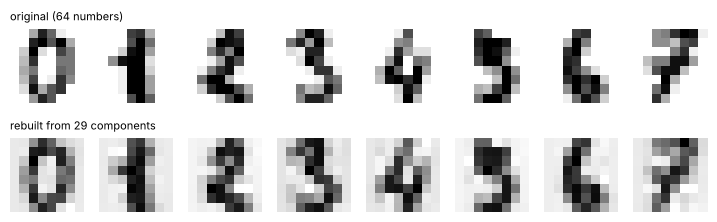

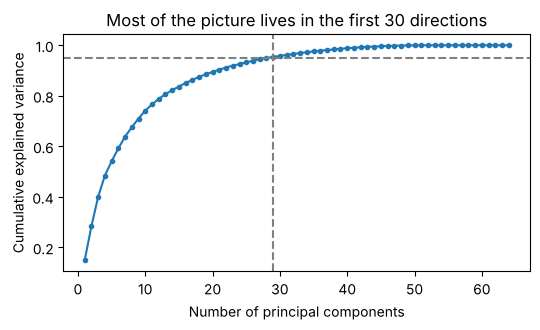

In [10]:
reconstructed = pca.inverse_transform(pca.transform(X_test.head(8)))

fig, axes = plt.subplots(2, 8, figsize=(9, 2.6))
for j in range(8):
    axes[0, j].imshow(X_test.iloc[j].to_numpy().reshape(8, 8), cmap="gray_r")
    axes[1, j].imshow(reconstructed[j].reshape(8, 8), cmap="gray_r")
    axes[0, j].axis("off")
    axes[1, j].axis("off")
axes[0, 0].set_title("original (64 numbers)", fontsize=8, loc="left")
axes[1, 0].set_title(f"rebuilt from {pca.n_components_} components", fontsize=8, loc="left")
plt.show()

plt.figure(figsize=(5.5, 3.4))
all_components = PCA(svd_solver="full").fit(X_dev)
plt.plot(np.arange(1, 65), np.cumsum(all_components.explained_variance_ratio_), marker=".")
plt.axhline(0.95, linestyle="--", color="grey")
plt.axvline(pca.n_components_, linestyle="--", color="grey")
plt.xlabel("Number of principal components")
plt.ylabel("Cumulative explained variance")
plt.title("Most of the picture lives in the first 30 directions")
plt.tight_layout()
plt.show()

### Inspect — PCA
**Choosing the budget (validation, training file only):**

| Setting | Components | Validation accuracy |
|---|---|---|
| All pixels | 64 | 0.9550 |
| 90% variance | 21 | 0.9487 |
| 95% variance | 29 | 0.9540 |
| 99% variance | 41 | 0.9561 |

90% costs about 0.6 points of accuracy; 95% is within 0.1 point of using every pixel; 99% gains only 0.2 points over 95% while needing 12 more components. **95% is the sweet spot**: less than half the features for essentially the same accuracy.

**Final test (official test file, used once):** the 95% pipeline keeps **29 of 64 components** (95.4% of variance) and scores **0.9477 — exactly the same as the full 64-pixel model (0.9477)**. PCA removed 55% of the input dimensions with no loss in downstream accuracy.

**Reconstruction and variance curve:** digits rebuilt from 29 components blur slightly but every digit remains clearly recognisable. The cumulative curve rises steeply and then flattens — the remaining **35 components together carry under 5% of the variance**, mostly fine pixel-level noise that the classifier doesn't need.

**Saved model check:** the reloaded pipeline predicts `[0, 1, 1, 3, 4]` for true labels `[0, 1, 2, 3, 4]` — it reloads and accepts raw 64-pixel input correctly; the third digit (a 2 read as a 1) is one of the ~5% of test digits the model gets wrong, consistent with 94.8% accuracy.

Save PCA and the classifier together, so the saved file accepts raw 64-pixel images directly.

In [11]:
model_path = MODELS / "digits_pca_logistic.joblib"
joblib.dump(final_model, model_path)

loaded = joblib.load(model_path)
first_digits = X_test.iloc[:5]
print("predicted:", loaded.predict(first_digits).tolist())
print("actual:   ", y_test.iloc[:5].tolist())

predicted: [0, 1, 1, 3, 4]
actual:    [0, 1, 2, 3, 4]


## Verification checklist
- [x] Features are standardized (`StandardScaler`) before clustering, and both the elbow and silhouette are reported (Part A).
- [x] The chosen number of clusters (k = 5) is justified with domain usefulness, not a single score (Part A inspect).
- [x] K-means and DBSCAN are compared, and the DBSCAN radius is stated (eps = 0.75, plus eps = 0.5 in *Try it yourself*).
- [x] PCA is fitted on training digits only (inside the `Pipeline`), and its components are judged by downstream test accuracy (Part C).
- [x] `models/digits_pca_logistic.joblib` reloads and predicts the first test digits (last cell of Part C).

## Check your understanding

**1. What does PCA optimize when it chooses its first principal component?**

It chooses the unit-length direction **w** that **maximizes the variance of the data projected onto it** — maximize Var(Xw) subject to ‖w‖ = 1, on mean-centred data. Equivalently, this is the direction that **minimizes the squared reconstruction error** when every point is approximated by its projection onto a single line. The solution is the eigenvector of the covariance matrix with the largest eigenvalue (the first right singular vector of the centred data), and that eigenvalue is the variance it captures. Each later component maximizes the remaining variance while staying orthogonal to the earlier ones.

**2. Why can standardization change which PCA directions appear most important?**

PCA ranks directions by raw variance, and variance depends on each feature's units and scale. Without standardization, a feature measured on a large scale (e.g. income in ringgit, with variance in the millions) dominates the covariance matrix, so the first component simply points along that feature — not because it carries the most structure, but because its numbers are biggest. Standardizing every feature to unit variance means PCA works on the **correlation** matrix instead, so components reflect how features co-vary rather than which units they happen to use. The ranking — and even the directions themselves — can therefore change completely. (In Part C the pixels already share one scale, 0–16 → 0–1, so dividing by 16 was enough; with the mixed-unit mall features, standardizing is essential.)

**3. Why should distances and apparent cluster sizes in a t-SNE or UMAP plot not be interpreted as exact properties of the original high-dimensional data?**

t-SNE and UMAP are non-linear methods designed to preserve **local neighbourhoods** — which points are close to which — not global geometry.
- **Distances between clusters** are not meaningful: the methods do not try to keep far-apart points proportionally far apart, so two clusters drawn far apart may not be more different than two drawn close together.
- **Cluster sizes and spreads** are distorted: t-SNE adapts its neighbourhood width to local density, so dense clusters get expanded and sparse ones contracted, making them look similar in size regardless of their true spread.
- **The layout depends on hyperparameters** (perplexity, `n_neighbors`, `min_dist`) and on random initialization — different settings or seeds can rearrange the picture.
- Squeezing many dimensions into two **must** distort something.

They are useful for spotting that local groupings exist, but any conclusion about distances, sizes or density should be checked in the original space (e.g. with silhouette scores or distances computed on the real features).